In [1]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.transforms import Bbox
import networkx as nx
import seaborn as sns
import pandas as pd

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

from src.simulation import (
    build_graph,
    build_kernel_bank,
    assign_kernels,
    build_initial_state,
    heterogeneous_contagion_process,
    get_activations,
    load_kernel,
    simple_kernel
)
from src.inference.inference import (
    fit_stan,
    get_posterior_draws,
)

import fig_settings as fs

fs.set_colors()
fs.set_fonts()

/Users/kbtang/Documents/research/het-ker/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RESULTS_DIR = Path('../results/cv/cv_basic')
df = pd.read_parquet(RESULTS_DIR / "_cv_curve.parquet")
sel = pd.read_parquet(RESULTS_DIR / "_cv_selection.parquet")

In [3]:
def rep_curves(df: pd.DataFrame, case: str) -> dict[int, pd.DataFrame]:
    """Extraction: one sorted (K, mean_lppd, se_lppd) frame per rep, for one case."""
    sub = df[df["dgp_label"] == case]
    return {int(rep): g.sort_values("K") for rep, g in sub.groupby("rep")}


def select_K_1se(curve: pd.DataFrame) -> int:
    """Most parsimonious K within 1 SE of the best K (higher lppd is better)."""
    c = curve.sort_values("K")
    best = c.loc[c["mean_lppd"].idxmax()]
    se = best["se_lppd"]
    if not np.isfinite(se):
        return int(best["K"])
    threshold = best["mean_lppd"] - se
    return int(c.loc[c["mean_lppd"] >= threshold, "K"].min())

def plot_curves(ax, df: pd.DataFrame, case: str, hero_rep: int, hero_color, leg_loc):
    curves = rep_curves(df, case)
    hero = curves[hero_rep]
    
    Ks = hero["K"].to_numpy()
    mean = hero["mean_lppd"].to_numpy()
    se = hero["se_lppd"].to_numpy()
    
    # 1-SE construction for hero rep
    imax = int(np.argmax(mean))
    threshold = mean[imax] - se[imax]
    sel_K = select_K_1se(hero)
    sel_mean = float(hero.loc[hero["K"] == sel_K, "mean_lppd"].iloc[0])

    # other reps in background
    for r, g in curves.items():
        if r == hero_rep:
            continue
        ax.plot(g["K"], g["mean_lppd"], color='darkgrey', lw=1.5, alpha=0.25, zorder=1)
        
    # hero rep: line + per-node SE band
    ax.fill_between(Ks, mean - se, mean + se, color=hero_color, alpha=0.3, zorder=2,
                    label="$\\pm 1$ SE")
    ax.plot(Ks, mean, color=hero_color, lw=2.0, marker="o", ms=6, zorder=4)

    # 1-SE threshold, selected K
    ax.axhline(threshold, color='grey', ls='-.', lw=1.3, zorder=3,
               label="1-SE threshold")
    ax.scatter([sel_K+0.015], [sel_mean], s=120, facecolors="none", edgecolors='black', lw=1.5, zorder=5)

    ax.set_xticks(sorted(df["K"].unique()))
    ax.set_xlabel("Num. mixture components, $K$")
    ax.set_ylabel("Mean LPPD / node")
    
    band = mpatches.Patch(color=hero_color, alpha=0.3)
    line = mlines.Line2D([0], [0], color=hero_color, marker="o", lw=2.0)
    thresh = mlines.Line2D([0], [0], color='grey', ls='-.', lw=1.3)
    ax.legend(
        handles = [(band, line), thresh],
        labels = ["mean $\\pm 1$ SE", "1-SE rule"],
        handlelength=1.5, handleheight=1.5,
        fancybox=False,
        loc=leg_loc,
        borderaxespad=0.2
    )
    # ax.legend(fancybox=False, loc='lower right')


# for confusion matrix
def confusion_K(sel: pd.DataFrame, cases: list[str], Ks: list[int]) -> np.ndarray:
    """Counts of CV-selected K (columns) per DGP case (rows)."""
    rows = []
    for case in cases:
        counts = sel.loc[sel["dgp_label"] == case, "selected_K"].value_counts()
        rows.append([int(counts.get(K, 0)) for K in Ks])
    return np.asarray(rows)


def plot_confusion(ax, sel, cases, true_Ks, Ks, colors, annot_counts=False):
    """Row-normalized confusion matrix of true vs. CV-selected number of kernels."""
    C = confusion_K(sel, cases, Ks)
    P = C / C.sum(axis=1, keepdims=True)

    for i in range(len(cases)):
        for j in range(len(Ks)):
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                facecolor=colors[i], alpha=P[i, j],
                edgecolor="white", lw=1.0, zorder=1,
            ))
            label = f"{C[i, j]}" if annot_counts else f"{100 * P[i, j]:.0f}%"
            ax.text(
                j + 0.5, i + 0.5, label,
                ha="center", va="center", zorder=2,
                color="white" if P[i, j] > 0.5 else "0.35",
                fontweight="bold" if i == j else "normal",
            )

    ax.add_patch(plt.Rectangle(
        (0, 0), len(Ks), len(cases),
        facecolor="none", edgecolor="0.35", lw=1.0, zorder=3,
    ))

    ax.set_xlim(0, len(Ks))
    ax.set_ylim(len(cases), 0) # row 0 on top
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(len(Ks)) + 0.5, [str(K) for K in Ks])
    ax.set_yticks(np.arange(len(cases)) + 0.5, [str(K) for K in true_Ks])
    ax.set_xlabel("Selected $K$")
    ax.set_ylabel("True $K$")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # tick labels carry the dgp colours of panels a and b
    for tick, color in zip(ax.get_yticklabels(), colors):
        tick.set_color(color)
        tick.set_fontweight("bold")

    return C

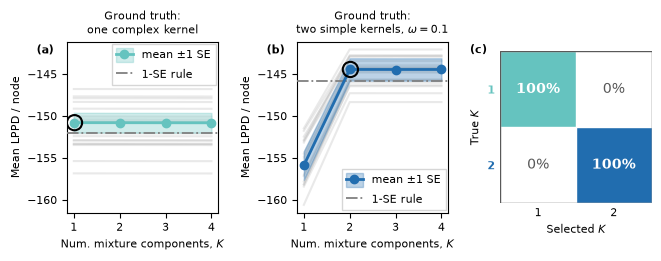

In [4]:
fig, axs = plt.subplots(
    1, 3,
    figsize=(6.5, 2.5),
    constrained_layout=True,
    gridspec_kw={"wspace": 0.1}
)
kmax = 28
nus = range(1, kmax + 1)

oneComplex_hero_rep = 0
plot_curves(axs[0], df, 'oneComplex', oneComplex_hero_rep, fs.palette[2], 'upper right')
axs[0].set_title("Ground truth:\none complex kernel")

twoSimple_hero_rep = 0
plot_curves(axs[1], df, 'twoSimpleOmega0.1', twoSimple_hero_rep, fs.palette[4], 'lower right')
axs[0].sharey(axs[1])
axs[1].set_title("Ground truth:\ntwo simple kernels, $\\omega=0.1$")

CASES   = ["oneComplex", "twoSimpleOmega0.1"]
TRUE_KS = [1, 2]
KS      = [1, 2]
COLORS  = [fs.palette[2], fs.palette[4]]   # same colours as panels a and b

C = plot_confusion(axs[2], sel, CASES, TRUE_KS, KS, COLORS)

axs[0].text(-0.2, 0.95, "(a)", transform=axs[0].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
axs[1].text(-0.2, 0.95, "(b)", transform=axs[1].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')
axs[2].text(-0.2, 1.01, "(c)", transform=axs[2].transAxes, fontsize=8, fontweight='bold', va='center', ha='left')

plt.savefig('../figs/figS2.svg', bbox_inches='tight')
plt.savefig('../figs/figS2.pdf', bbox_inches='tight')